In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. İşlenmiş temiz veriyi yükleyelim
df = pd.read_csv('../data/processed/df_merged.csv')
df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'])

# 2. Temel zaman bileşenlerini çıkaralım
df['hour'] = df['DATE_TIME'].dt.hour
df['minute'] = df['DATE_TIME'].dt.minute
df['day_of_week'] = df['DATE_TIME'].dt.dayofweek
df['day_of_year'] = df['DATE_TIME'].dt.dayofyear

# 3. 15 dakikalık periyot için gün içi dakika indeksi (0 - 1439 arası)
minute_of_day = df['hour'] * 60 + df['minute']

# 4. Döngüsel (Cyclical) Zaman Kodlaması (Sin/Cos Dönüşümü)
# Günün saati için (24 saatlik periyot)
df['sin_time'] = np.sin(2 * np.pi * minute_of_day / 1440.0)
df['cos_time'] = np.cos(2 * np.pi * minute_of_day / 1440.0)

# Yılın günü için mevsimsellik (365 günlük periyot)
df['sin_day'] = np.sin(2 * np.pi * df['day_of_year'] / 365.25)
df['cos_day'] = np.cos(2 * np.pi * df['day_of_year'] / 365.25)

print("Döngüsel zaman özellikleri eklendi.")
display(df[['DATE_TIME', 'hour', 'minute', 'sin_time', 'cos_time']].head())

Döngüsel zaman özellikleri eklendi.


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_4712\3183301905.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['day_of_week'] = df['DATE_TIME'].dt.dayofweek
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_4712\3183301905.py:14: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df['day_of_year'] = df['DATE_TIME'].dt.dayofyear


,DATE_TIME,hour,minute,sin_time,cos_time
0,2020-05-15 00:00:00,0,0,0.000000,1.000000
1,2020-05-15 00:15:00,0,15,0.065403,0.997859
2,2020-05-15 00:30:00,0,30,0.130526,0.991445
3,2020-05-15 00:45:00,0,45,0.195090,0.980785
4,2020-05-15 01:00:00,1,0,0.258819,0.965926


In [2]:
# 1. AC_POWER (hedef değişkenimiz) için Lag özellikleri
df['ac_power_lag_1'] = df['AC_POWER'].shift(1)  # 15 dk önceki güç
df['ac_power_lag_2'] = df['AC_POWER'].shift(2)  # 30 dk önceki güç
df['ac_power_lag_4'] = df['AC_POWER'].shift(4)  # 1 saat önceki güç

# 2. Işınım (IRRADIATION) ve Panel Sıcaklığı için Lag özellikleri
df['irradiation_lag_1'] = df['IRRADIATION'].shift(1)
df['module_temp_lag_1'] = df['MODULE_TEMPERATURE'].shift(1)

# 3. Hareketli İstatistikler (Son 1 saatin ortalaması - 4 periyot)
df['ac_power_rolling_mean_1h'] = df['AC_POWER'].rolling(window=4).mean()
df['irradiation_rolling_mean_1h'] = df['IRRADIATION'].rolling(window=4).mean()

# Lag işlemlerinden dolayı ilk 4 satırda NaN oluşur, bunları temizleyelim
df_features = df.dropna().reset_index(drop=True)

print(f"Lag ve rolling sonrası veri boyutu: {df_features.shape}")

Lag ve rolling sonrası veri boyutu: (3153, 23)


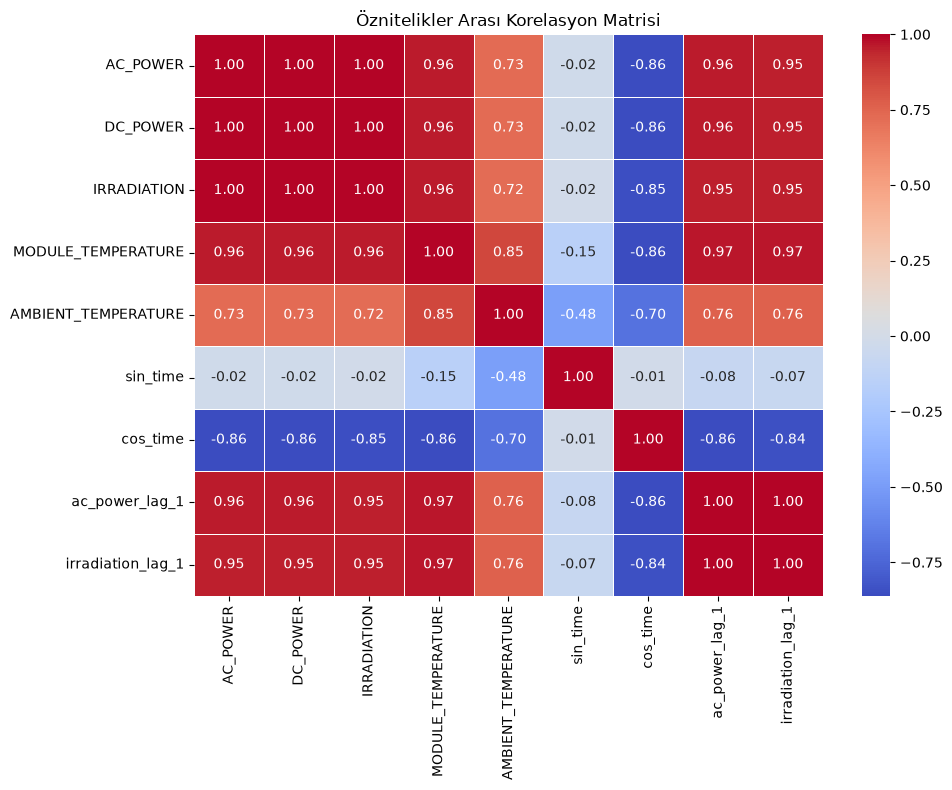

Modellemeye hazır 'df_features.csv' başarıyla kaydedildi!


In [3]:
# 1. Önemli özellikler arası korelasyon
corr_cols = [
    'AC_POWER', 'DC_POWER', 'IRRADIATION', 
    'MODULE_TEMPERATURE', 'AMBIENT_TEMPERATURE',
    'sin_time', 'cos_time', 'ac_power_lag_1', 'irradiation_lag_1'
]

plt.figure(figsize=(10, 8))
sns.heatmap(df_features[corr_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Öznitelikler Arası Korelasyon Matrisi')
plt.tight_layout()
plt.show()

# 2. Modellemeye hazır nihai veriyi kaydetme
df_features.to_csv('../data/processed/df_features.csv', index=False)
print("Modellemeye hazır 'df_features.csv' başarıyla kaydedildi!")